<a href="https://colab.research.google.com/github/jppeirce/DSC210-Foundations-of-Data-Science/blob/main/Homework/HW05-unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 5 SOLUTIONS: Finding Groups in River Water

*Instructor version. Do not distribute.*

**DSC 210 Foundations of Data Science**

*Covers Module 9 (unsupervised learning).*

```
ASK  ->  GET  ->  EXPLORE  ->  [ MODEL ]  ->  COMMUNICATE
```

References:
- Module 9 course notebook (k-means, choosing k, hierarchical clustering, DBSCAN, PCA)
- Huber, *Hands-on Introduction to Data Science with Python* (CC BY-NC-SA 4.0): [Clustering](https://florian-huber.github.io/data_science_course/notebooks/12_clustering.html) and [Clustering beyond the basics](https://florian-huber.github.io/data_science_course/notebooks/12b_clustering_beyond_the_basics.html) (Gaussian mixture models, Ward linkage)
- Water quality data: summary statistics from the Upper Mississippi River Restoration Program's Long Term Resource Monitoring (LTRM) element, Pool 8, `csv_data/pool8water.csv`

*Last major revision: 2026-10-25*

## Key Concepts

- Carry out k-means by hand in two dimensions, and check it in code
- Explain why clustering needs **scaled** features, and see what goes wrong without scaling
- Choose `k`, read clusters through their centroids, and picture them with PCA
- Compare k-means with hierarchical (Ward) clustering, DBSCAN, and a Gaussian mixture model
- Match algorithms to the shapes of data they can and cannot find
- Report what a clustering does and does not show, including that every algorithm finds clusters even in pure noise

## Instructions

**Total: 50 points.** Point values are listed with each problem.

- Cells marked `# RUN-TOGETHER` are complete; run them and read the output.
- Cells marked `# FILL-IN` contain blanks written as `____`. They raise an error until every blank is replaced. Lines marked `# YOUR CODE` are yours to write.
- Run the cells **in order**. Later problems use the table `water` and the scaled array `X` from Part A.
- Every figure must include a title and labeled axes.
- Most of the credit rides on your written answers. Quote specific numbers from your output.
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

---
## Part 0. The assignment and the data (2 points)
---

**The scenario.** You are interning with river scientists who monitor Pool 8 of the Mississippi River, the stretch that runs past La Crosse. Four times a year they sample the water in four kinds of habitat. A biologist asks:

> *"If you ignored the calendar, would the water measurements alone sort these samples into seasons? And which samples don't fit any group?"*

This is a natural question for **unsupervised learning**: the seasons are labels we *have*, but we will hide them from every algorithm, cluster on the measurements alone, and only then compare, exactly as Module 9 did with the penguin species.

**About the data.** Each row of `pool8water.csv` is **one summary statistic** (the median, a percentile, or the number of samples `n`) for one combination of year, season, and habitat. We use only the **medians**.

| Column | Meaning |
| --- | --- |
| `YEAR` | year sampled (1993 to 2025) |
| `SEASON` | sampling season: `SP` spring, `SM` summer, `FL` fall, `WN` winter |
| `STRATUM` | habitat: `MC` main channel, `SC` side channel, `BWC` contiguous backwater, `IMP` impounded area, `POOL` the whole pool |
| `STAT` | which summary statistic the row holds: `median`; `p10`, `p25`, `p75`, `p90` (the 10th, 25th, 75th, and 90th percentiles); or `n`, the number of measurements the summary is based on |
| `TEMP` | water temperature (degrees C) |
| `DO` | dissolved oxygen (mg/L) |
| `COND` | specific conductance (microsiemens per cm) |
| `PH` | pH |
| `TURB` | turbidity (NTU) |
| `SS` | suspended solids (mg/L) |
| `CHLCAL` | chlorophyll *a*, a measure of algae (micrograms per L) |
| `TN`, `TP` | total nitrogen and total phosphorus (mg/L) |

In [1]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

url = 'https://raw.githubusercontent.com/jppeirce/DSC210-Foundations-of-Data-Science/main/csv_data/pool8water.csv'
pool8 = pd.read_csv(url)
print('shape:', pool8.shape)
pool8.head(8)

shape: (3720, 19)


,YEAR,SEASON,STRATUM,STAT,TEMP,DO,COND,PH,TURB,SS,VSS,CHLCAL,TN,NOX,NHX,TP,SRP,ICE,SNOW
0,1993,FL,BWC,median,15.30,9.15,441.5,7.60,15.0,18.30,6.90,16.38,3.41,1.35,0.04,0.18,0.10,NaN,NaN
1,1993,FL,BWC,n,60.00,60.00,60.0,58.00,60.0,32.00,32.00,19.00,31.00,32.00,32.00,32.00,32.00,0.0,0.0
2,1993,FL,BWC,p10,13.85,4.90,375.5,7.00,10.5,9.75,5.35,12.20,1.88,0.10,0.01,0.15,0.01,NaN,NaN
3,1993,FL,BWC,p25,14.60,7.95,396.5,7.20,13.0,14.50,6.10,14.81,2.80,0.37,0.02,0.17,0.05,NaN,NaN
4,1993,FL,BWC,p75,15.90,10.05,482.0,7.90,21.0,21.50,8.50,17.81,3.61,1.66,0.08,0.19,0.11,NaN,NaN
5,1993,FL,BWC,p90,16.20,10.55,525.0,8.05,27.0,43.15,14.10,28.69,4.33,1.90,0.11,0.23,0.12,NaN,NaN
6,1993,FL,IMP,median,15.30,8.80,460.0,7.60,15.0,18.85,6.55,17.33,3.36,1.78,0.04,0.17,0.11,NaN,NaN
7,1993,FL,IMP,n,23.00,23.00,23.0,23.00,23.0,12.00,12.00,10.00,12.00,12.00,12.00,12.00,12.00,0.0,0.0


In [2]:
# RUN-TOGETHER  (Problem 0): what kinds of rows are there?
print(pool8['STAT'].value_counts())

# All rows for one year, season, and habitat: fall 1993, contiguous backwater
one = pool8[(pool8['YEAR'] == 1993) & (pool8['SEASON'] == 'FL') & (pool8['STRATUM'] == 'BWC')]
one[['YEAR', 'SEASON', 'STRATUM', 'STAT', 'TEMP', 'DO', 'TURB']]

STAT
median    620
n         620
p10       620
p25       620
p75       620
p90       620
Name: count, dtype: int64


,YEAR,SEASON,STRATUM,STAT,TEMP,DO,TURB
0,1993,FL,BWC,median,15.30,9.15,15.0
1,1993,FL,BWC,n,60.00,60.00,60.0
2,1993,FL,BWC,p10,13.85,4.90,10.5
3,1993,FL,BWC,p25,14.60,7.95,13.0
4,1993,FL,BWC,p75,15.90,10.05,21.0
5,1993,FL,BWC,p90,16.20,10.55,27.0


**Problem 0.** (2 points)

(a) Report the shape. How many kinds of row does the `STAT` column hold, and how many rows of each kind?

(b) The six rows in the last output all describe the same water: the backwater in fall 1993. Using the `STAT` column and the data table above, explain what each of these `TEMP` values means: 15.30, 60.00, and 16.20.

(c) Why would it be a mistake to compute the average `TEMP` of the whole table?

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> (a) Shape (3720, 19). `STAT` holds six kinds of row (`median`, `n`, `p10`, `p25`, `p75`, `p90`), with 620 rows of each.
>
> (b) 15.30 is the median water temperature of the fall 1993 backwater measurements (degrees C). 60.00 is not a temperature: it is `n`, the number of temperature measurements behind the summary. 16.20 is the 90th percentile: 90% of those measurements were at or below 16.2 degrees C.
>
> (c) The `TEMP` column mixes medians, percentiles, and sample counts, so its average mixes temperatures with counts (such as 60) and with low and high percentiles. The result is not the temperature of anything. We must first keep one kind of row.

---
## Part A. k-means, by hand and on the river (10 points)
---

### Problem A1. k-means by hand in two dimensions (3 points)

Module 9 ran k-means by hand on a line. Here are six points in a plane, with `k = 2`, and a deliberately **bad** start: both centroids in the same corner.

| point | P1 | P2 | P3 | P4 | P5 | P6 |
| --- | --- | --- | --- | --- | --- | --- |
| (x, y) | (1, 1) | (2, 1) | (1, 2) | (6, 5) | (7, 5) | (6, 6) |

Starting centroids: $c_1 = (1, 1)$ and $c_2 = (2, 1)$. Use **Euclidean** distance, $\sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}$.

**(a) Iteration 1.** Fill in the distances (two decimals) and assignments. Then compute the new centroids, and the WCSS of this assignment measured from the new centroids.

| point | distance to $c_1$ | distance to $c_2$ | cluster |
| --- | --- | --- | --- |
| P1 (1, 1) |  |  |  |
| P2 (2, 1) |  |  |  |
| P3 (1, 2) |  |  |  |
| P4 (6, 5) |  |  |  |
| P5 (7, 5) |  |  |  |
| P6 (6, 6) |  |  |  |

New $c_1$ = ________  New $c_2$ = ________  WCSS = ________

**(b) Iteration 2.** Using the new centroids, which point changes cluster? Give the new centroids and the WCSS.

**(c)** Does iteration 3 change anything? What did the bad start cost, and which `KMeans` argument protects against bad starts?

**Your answer:**

(a)

(b)

(c)

In [3]:
# RUN-TOGETHER  (Problem A1): check your final answer
P = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 5], [6, 6]], dtype=float)
start = np.array([[1, 1], [2, 1]], dtype=float)

km_hand = KMeans(n_clusters=2, init=start, n_init=1).fit(P)   # init= sets the starting centroids
print('labels    :', km_hand.labels_)
print('centroids :', km_hand.cluster_centers_.round(3).tolist())
print('WCSS      :', round(km_hand.inertia_, 3))
print('iterations:', km_hand.n_iter_)

labels    : [0 0 0 1 1 1]
centroids : [[1.333, 1.333], [6.333, 5.333]]
WCSS      : 2.667
iterations: 3


> **SOLUTION**
>
> (a)
>
> | point | to $c_1$ | to $c_2$ | cluster |
> | --- | --- | --- | --- |
> | P1 | 0.00 | 1.00 | 1 |
> | P2 | 1.00 | 0.00 | 2 |
> | P3 | 1.00 | 1.41 | 1 |
> | P4 | 6.40 | 5.66 | 2 |
> | P5 | 7.21 | 6.40 | 2 |
> | P6 | 7.07 | 6.40 | 2 |
>
> New $c_1$ = mean of P1, P3 = (1, 1.5). New $c_2$ = mean of P2, P4, P5, P6 = (5.25, 4.25). WCSS = 0.25 + 0.25 (cluster 1) + 21.125 + 1.125 + 3.625 + 3.625 (cluster 2) = **25.0**.
>
> (b) P2 moves to cluster 1 (distance 1.12 to (1, 1.5) vs 4.60 to (5.25, 4.25)). New centroids (1.333, 1.333) and (6.333, 5.333); WCSS = 1.333 + 1.333 = **2.667**.
>
> (c) No point changes, so k-means has converged (the code reports 3 iterations, counting the final check). The bad start cost an extra iteration here; on other data a bad start can leave k-means stuck in a worse answer for good. `n_init=10` reruns from ten random starts and keeps the lowest WCSS.

### Problem A2. Get the rows that mean something (3 points)

Keep only the **median** rows, drop the `POOL` rows (they appear to summarize the whole pool, so keeping them would count the same water twice), and drop rows with any missing value in the nine measurement columns.

In [4]:
features = ['TEMP', 'DO', 'COND', 'PH', 'TURB', 'SS', 'CHLCAL', 'TN', 'TP']

medians = pool8[pool8['STAT'] == 'median']
water = medians[medians['STRATUM'] != 'POOL']
water = water.dropna(subset=features).copy()

print('median rows      :', len(medians))
print('without POOL     :', len(medians[medians['STRATUM'] != 'POOL']))
print('after dropping NA:', len(water))
print(pd.crosstab(water['STRATUM'], water['SEASON']))

median rows      : 620
without POOL     : 496
after dropping NA: 488
SEASON   FL  SM  SP  WN
STRATUM                
BWC      30  32  30  30
IMP      30  32  30  30
MC       30  32  30  30
SC       30  32  30  30


(a) In one sentence: what does **one row** of `water` represent?

(b) How many rows remain at each step? Use the crosstab: is the design roughly balanced across seasons and habitats?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> Blanks: `'median'`, `!=`, `features`.
>
> (a) One row is the median of the samples taken in one habitat (stratum) of Pool 8 during one season of one year.
>
> (b) 620 median rows, 496 without POOL, 488 after dropping missing values (the 8 lost rows are fall 1996, missing `TP`, and winter 1996, missing `SS`, one per habitat). The design is nearly balanced: each habitat has 30 rows per season (32 in summer), so the seasons have 120 to 128 rows.

### Problem A3. Scale first, or not? (4 points)

The biologist's first guess is that the water has two states: winter and everything else. Run k-means with `k = 2` twice, on the raw measurements and on scaled ones, and compare each clustering with the seasons the algorithm never saw.

In [5]:
km_raw = KMeans(n_clusters=2, n_init=10, random_state=0).fit(water[features])
water['raw2'] = km_raw.labels_
print(pd.crosstab(water['raw2'], water['SEASON']))
print(water.groupby('raw2')[features].median().round(1))

SEASON  FL  SM  SP   WN
raw2                   
0       51  80  30  102
1       69  48  90   18
      TEMP    DO   COND   PH  TURB    SS  CHLCAL   TN   TP
raw2                                                      
0     13.2  11.1  457.0  8.1   5.0   6.0    10.3  2.6  0.1
1     12.8  10.4  371.5  8.2  10.0  13.0    15.8  1.8  0.1


In [6]:
X = StandardScaler().fit_transform(water[features])

km2 = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)
water['scaled2'] = km2.labels_
print(pd.crosstab(water['scaled2'], water['SEASON']))
print(water.groupby('scaled2')[features].median().round(1))

SEASON    FL   SM   SP   WN
scaled2                    
0          7    0    3  120
1        113  128  117    0
         TEMP    DO   COND   PH  TURB    SS  CHLCAL   TN   TP
scaled2                                                      
0         0.1  12.8  455.5  7.9   3.0   2.1     3.5  2.6  0.1
1        14.7   9.9  402.8  8.3  10.0  13.0    18.0  1.9  0.1


(a) Does the **unscaled** clustering separate winter from the other seasons? Which single feature differs most between its two clusters, and why does that feature dominate the distance? (Hint: compare the ranges of the columns.)

(b) Does the **scaled** clustering separate winter? Quote the crosstab.

(c) Using the medians, describe the winter cluster in words. Which measurements set it apart?

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Blanks: `features`, `2`.
>
> (a) No. Each unscaled cluster mixes all four seasons (for example 102 winter rows and 51 fall rows in one, 18 winter and 90 spring in the other). The clusters differ mainly in `COND` (medians about 457 vs 372), while other medians are similar. Conductance values span about 400 units (204 to 606), far more than pH (2.2 units) or total phosphorus (0.21), so squared distances are almost entirely conductance differences.
>
> (b) Yes, almost perfectly: one cluster holds all 120 winter rows plus 7 fall and 3 spring rows; the other holds the remaining 358 rows (113 fall, 128 summer, 117 spring) and no winter rows.
>
> (c) Compared with the other cluster, the winter cluster has near-freezing water (median 0.1 vs 14.7 degrees C), more dissolved oxygen (12.8 vs 9.9 mg/L), very clear water (turbidity 3 vs 10, suspended solids 2.1 vs 13.0), little algae (chlorophyll 3.5 vs 18.0), and somewhat higher conductance (456 vs 403) and nitrogen (2.6 vs 1.9). Cold water holds more oxygen; the low algae and turbidity are consistent with ice cover and low flow, though the data alone cannot show why.

---
## Part B. More than two groups (10 points)
---

### Problem B1. How many clusters? (3 points)

k = 1   WCSS =  4392.0
k = 2   WCSS =  3077.5
k = 3   WCSS =  2484.2
k = 4   WCSS =  2079.7
k = 5   WCSS =  1865.1
k = 6   WCSS =  1693.5
k = 7   WCSS =  1564.4
k = 8   WCSS =  1461.8


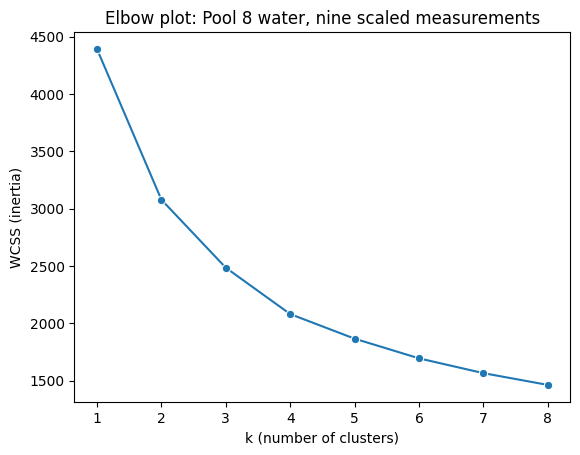

In [7]:
ks = range(1, 9)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

for k, w in zip(ks, wcss):
    print(f'k = {k}   WCSS = {w:7.1f}')

sns.lineplot(x=list(ks), y=wcss, marker='o')
plt.title('Elbow plot: Pool 8 water, nine scaled measurements')
plt.xlabel('k (number of clusters)')
plt.ylabel('WCSS (inertia)')
plt.xticks(list(ks))
plt.show()

(a) Compute the drop in WCSS from k = 1 to 2, 2 to 3, and 3 to 4. Which drop is largest?

(b) Is there one clear elbow? Compare this plot with the penguin elbow in Module 9. What does a gradual curve suggest about the structure of the data?

(c) There are four seasons. Give one reason, from what you know about rivers through the year, why four clusters need not line up with four seasons.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Blank: `X`.
>
> (a) WCSS: 4392.0, 3077.5, 2484.2, 2079.7, ... The drops are 1314.5 (1 to 2), 593.3 (2 to 3), and 404.5 (3 to 4). The first is by far the largest.
>
> (b) The only sharp bend is at k = 2 (winter vs the rest); after that the curve declines gradually with no clear elbow. A gradual curve suggests that, apart from winter, conditions change continuously rather than falling into well-separated groups.
>
> (c) Spring and fall have overlapping temperatures, and conditions in any season vary with year-to-year flow, so neighboring seasons can look alike; a single season can also contain very different conditions (for example a clear summer and an algae-rich summer). Accept any reasonable reason.

### Problem B2. Reading four clusters (4 points)

In [8]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X)
water['cluster'] = km4.labels_

print(water['cluster'].value_counts().sort_index())
print(pd.crosstab(water['cluster'], water['SEASON']))
print(water.groupby('cluster')[features].median().round(2))

cluster
0    126
1    159
2    108
3     95
Name: count, dtype: int64
SEASON   FL  SM  SP   WN
cluster                 
0         0   0   6  120
1        75  70  14    0
2        30  33  45    0
3        15  25  55    0
          TEMP     DO   COND    PH  TURB     SS  CHLCAL    TN    TP
cluster                                                            
0         0.10  12.95  457.5  7.88   3.0   2.10    3.68  2.61  0.06
1        15.90   9.15  410.0  8.20   6.0   6.84   11.63  1.61  0.13
2        13.75   9.43  389.0  8.00  14.0  17.98   14.28  2.54  0.14
3        13.70  12.00  404.5  8.70  12.0  17.10   44.51  1.81  0.11


(a) Which cluster is the winter cluster? Is it essentially the same group you found in A3?

(b) For each of the other three clusters, name the season(s) it draws mostly from and the measurements that set it apart. Then give each cluster a short descriptive name. (Naming a cluster is *interpretation*: say what the numbers show, not what causes them.)

(c) The crosstab against `STRATUM` is not printed above. Predict whether the clusters separate habitats as cleanly as they separate winter, then check with one line of code.

**Your answer:**

(a)

(b)

(c)

In [9]:
pd.crosstab(water['cluster'], water['STRATUM'])

STRATUM,BWC,IMP,MC,SC
cluster,,,,
0,30,33,32,31
1,51,42,34,32
2,20,24,32,32
3,21,23,24,27


> **SOLUTION**
>
> Blanks: `'SEASON'`, `median`.
>
> Cluster numbers depend on the run; the descriptions below use `random_state=0`.
>
> (a) Cluster 0 (126 rows): all 120 winter rows plus 6 spring rows, essentially the A3 winter cluster (which had 120 winter rows plus 10 others).
>
> (b)
> - Cluster 1 (159 rows; 75 fall, 70 summer, 14 spring): warmest (median about 16 degrees C), clearest of the open-water clusters (turbidity 6, suspended solids about 7), moderate algae (chlorophyll about 12). A name like "warm and clear".
> - Cluster 2 (108 rows; 45 spring, 33 summer, 30 fall): turbid, with the highest suspended solids (about 18) and turbidity (14), the most nitrogen and phosphorus among open-water clusters, and moderate algae. "Muddy water".
> - Cluster 3 (95 rows; 55 spring, 25 summer, 15 fall): by far the most algae (chlorophyll about 45), the highest pH (8.7), and high dissolved oxygen (12). "Algae-rich".
>
> The algae-rich cluster's high pH and oxygen are consistent with photosynthesis by algae, but that is an interpretation the data cannot confirm.
>
> (c) The clusters do not separate habitats: every cluster has between 20 and 51 rows from each habitat. Season, not habitat, drives most of the structure (the backwater habitat is somewhat over-represented in cluster 1, with 51 rows).

### Problem B3. Picture the clusters with PCA (3 points)

Nine dimensions cannot be drawn. Reduce the scaled data to two principal components, then draw the same points twice: colored by cluster, and colored by season.

variance explained: [0.414 0.22 ] | together: 0.634
         PC1   PC2
TEMP    0.42 -0.24
DO     -0.26  0.58
COND   -0.20 -0.10
PH      0.25  0.46
TURB    0.43  0.08
SS      0.44  0.16
CHLCAL  0.33  0.45
TN     -0.17 -0.00
TP      0.38 -0.38


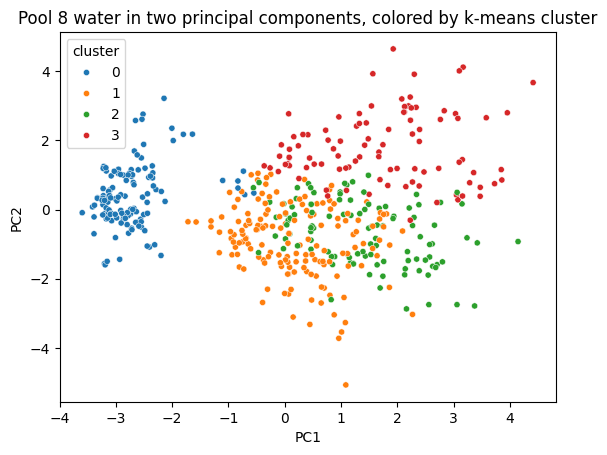

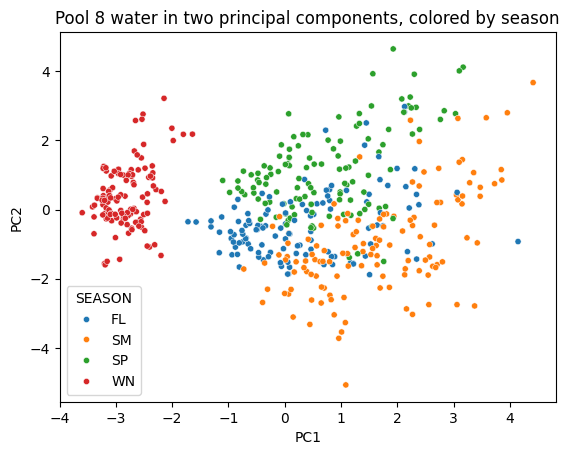

In [10]:
pca = PCA(n_components=2).fit(X)
pcs = pca.transform(X)
water['PC1'] = pcs[:, 0]
water['PC2'] = pcs[:, 1]
print('variance explained:', pca.explained_variance_ratio_.round(3), '| together:', round(pca.explained_variance_ratio_.sum(), 3))
print(pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2']).round(2))

sns.scatterplot(data=water, x='PC1', y='PC2', hue='cluster', palette='tab10', s=20)
plt.title('Pool 8 water in two principal components, colored by k-means cluster')
plt.show()

sns.scatterplot(data=water, x='PC1', y='PC2', hue='SEASON', palette='tab10', s=20)
plt.title('Pool 8 water in two principal components, colored by season')
plt.show()

(a) How much of the variation do the two components keep together?

(b) Use the loadings: which measurements push a sample toward high PC1? Toward high PC2?

(c) Compare the two pictures. Which season stands apart in its own region, and which seasons overlap?

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Blank: `'cluster'`.
>
> (a) PC1 0.414 and PC2 0.220, together 0.634: about 63% of the variation in the nine scaled measurements.
>
> (b) High PC1: warm, turbid water with more suspended solids, phosphorus, and chlorophyll (loadings about 0.33 to 0.44), and lower oxygen and conductance. High PC2: high oxygen (0.58), chlorophyll (0.45), and pH (0.46), with lower phosphorus (-0.38). PC2 roughly tracks the algae-rich, high-oxygen samples. (Naming components is interpretation.)
>
> (c) Winter occupies its own region on the low-PC1 side, matching the winter cluster. Spring, summer, and fall overlap heavily, and the boundaries between the three open-water clusters cut across them rather than following the seasons.

---
## Part C. Other ways to cluster the same water (12 points)
---

### Problem C1. Hierarchical clustering with Ward linkage (3 points)

Module 9 built a dendrogram with **single** linkage. Huber's chapter uses **Ward** linkage, which merges the two clusters whose union increases the within-cluster sum of squares the least. It favors compact clusters, much like k-means, but builds the whole tree first.

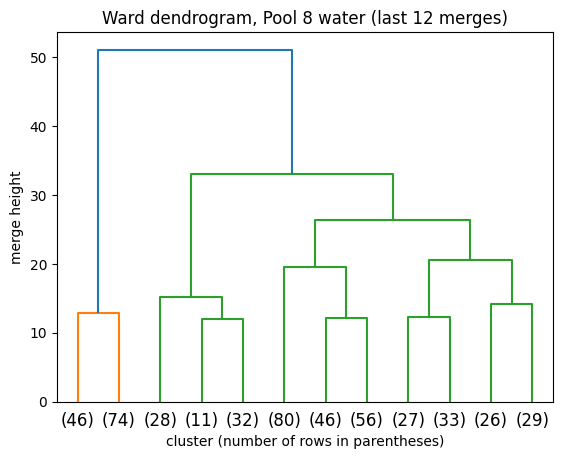

heights of the last five merges: [19.6 20.6 26.4 33.  51. ]
SEASON   FL   SM   SP   WN
ward2                     
1         0    0    0  120
2       120  128  120    0
cluster    0    1   2   3
ward4                    
1        120    0   0   0
2          0    0   3  68
3          0  146  33   3
4          6   13  72  24


In [11]:
Z = linkage(X, method='ward')

dendrogram(Z, truncate_mode='lastp', p=12)
plt.title('Ward dendrogram, Pool 8 water (last 12 merges)')
plt.xlabel('cluster (number of rows in parentheses)')
plt.ylabel('merge height')
plt.show()
print('heights of the last five merges:', Z[-5:, 2].round(1))

water['ward2'] = fcluster(Z, 2, criterion='maxclust')
water['ward4'] = fcluster(Z, 4, criterion='maxclust')
print(pd.crosstab(water['ward2'], water['SEASON']))
print(pd.crosstab(water['ward4'], water['cluster']))

(a) The last merge is much higher than the ones before it. What does that gap say, and what does the two-cluster cut contain?

(b) Compare the four-cluster Ward cut with the four k-means clusters. Which group do the two methods agree on exactly, and where do they disagree?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> Blanks: `'ward'`, `4`.
>
> (a) The last merge heights are 19.6, 20.6, 26.4, 33.0, and 51.0: the final merge (51.0) is far above the rest. Two very different groups exist, joined only at the top. The two-cluster cut is exactly winter (all 120 winter rows) vs every spring, summer, and fall row (368).
>
> (b) Both methods find the same 120-row winter group (Ward cluster 1 is entirely k-means cluster 0; the 6 spring rows k-means put in the winter cluster go to another Ward cluster). The open-water groups correspond only roughly: Ward cluster 2 is mostly the algae-rich k-means cluster (68 of 71), Ward 3 is mostly warm and clear (146 of 182), and Ward 4 mixes the turbid cluster (72) with pieces of the others. The methods agree on the sharp boundary and disagree where conditions blend.

### Problem C2. DBSCAN as a detector of unusual samples (3 points)

In [12]:
for eps in [1.0, 1.5, 2.0]:
    db = DBSCAN(eps=eps, min_samples=5).fit(X)
    n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    print(f'eps={eps}  clusters={n_clusters}  noise={(db.labels_ == -1).sum()}')

db = DBSCAN(eps=1.5, min_samples=5).fit(X)
water['db'] = db.labels_
show = ['YEAR', 'SEASON', 'STRATUM', 'TEMP', 'TURB', 'CHLCAL', 'TP', 'DO']
print(water[water['db'] == -1][show].sort_values('CHLCAL', ascending=False).head(8))
print(pd.crosstab(water['db'], water['SEASON']))

eps=1.0  clusters=10  noise=272
eps=1.5  clusters=3  noise=46
eps=2.0  clusters=1  noise=2
      YEAR SEASON STRATUM   TEMP  TURB  CHLCAL    TP     DO
1392  2006     SM      MC  28.20  17.0  120.94  0.13  12.80
1404  2006     SM      SC  28.35  16.0   98.02  0.12  11.35
2472  2015     SM      MC  26.40  11.0   92.34  0.11  11.30
246   1995     SP     IMP  11.90  16.0   77.70  0.06  15.80
3294  2022     SM      SC  26.15  16.0   77.05  0.14  12.65
1152  2004     SM      MC  25.60  15.0   64.79  0.10  12.80
1380  2006     SM     BWC  27.40  13.0   64.18  0.20   6.90
3690  2025     WN     BWC   0.60   5.5   53.45  0.05  18.30
SEASON   FL  SM   SP   WN
db                       
-1        2  21   11   12
 0      118  99  104  108
 1        0   8    0    0
 2        0   0    5    0


(a) Record the number of clusters and noise points for each `eps`. Why does DBSCAN never find the four groups that k-means reported? (Think about how DBSCAN builds a cluster by chaining neighbors.)

(b) With `eps = 1.5`, look at the noise points with the most chlorophyll. What do they have in common? Why might a biologist find this list more useful than the clusters themselves?

**Your answer:**

(a)

(b)

> **SOLUTION**
>
> Blanks: `1.5`, `-1`.
>
> (a) eps 1.0: 10 clusters, 272 noise points; eps 1.5: 3 clusters, 46 noise; eps 2.0: 1 cluster, 2 noise. Seasons change gradually, so dense chains of similar samples connect spring to summer to fall, and even to winter once `eps` is large enough. DBSCAN joins everything a chain reaches, so it never splits the open-water conditions into separate groups; with small `eps` it shatters them into fragments and noise instead. (At eps 1.5 the main cluster contains rows from every season.)
>
> (b) The top noise points are mostly summer samples with extremely high chlorophyll (for example 2006 summer main channel, about 121, and side channel, about 98; 2015 summer main channel, about 92), warm water, and high turbidity. They are unusual samples, possibly algae blooms. A list of unusual sampling events is something a biologist can follow up on; the noise label is DBSCAN's version of "this does not fit any group."

### Problem C3. Soft clustering with a Gaussian mixture (3 points)

k-means gives each sample exactly one cluster. A **Gaussian mixture model** (Huber, *Clustering beyond the basics*) describes each cluster as a bell-shaped cloud that can be stretched and tilted, and gives each sample a **probability** of belonging to each cluster.

In [13]:
gmm = GaussianMixture(n_components=4, random_state=0).fit(X)
probs = gmm.predict_proba(X)
water['gmm'] = gmm.predict(X)
water['gmm_conf'] = probs.max(axis=1)

print(pd.crosstab(water['gmm'], water['SEASON']))
print('samples with confidence below 0.8:', (water['gmm_conf'] < 0.8).sum())
print(water[water['gmm_conf'] < 0.8]['SEASON'].value_counts())
print(water.groupby('SEASON')['gmm_conf'].mean().round(3))

SEASON  FL  SM  SP   WN
gmm                    
0        0   0   0  118
1       61  67   6    0
2       38  36  60    0
3       21  25  54    2
samples with confidence below 0.8: 30
SEASON
FL    18
SP     7
SM     5
Name: count, dtype: int64
SEASON
FL    0.930
SM    0.972
SP    0.964
WN    1.000
Name: gmm_conf, dtype: float64


(a) Does the mixture model also find a winter group?

(b) Which season holds most of the uncertain samples, and which season has the most confident ones? Why does that make sense?

(c) Name one thing a membership probability tells you that a k-means label cannot.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Blanks: `1`, `mean`.
>
> (a) Yes: one component holds 118 of the 120 winter rows and nothing else.
>
> (b) 30 samples have confidence below 0.8: 18 fall, 7 spring, 5 summer, and no winter. Fall has the lowest average confidence (0.930) and winter the highest (1.000). Fall is a transition between summer and winter conditions, so its samples sit between groups; winter is so distinct that every winter sample is classified with near certainty.
>
> (c) A probability shows how strongly a sample belongs: a sample at 0.47 is nearly split between two clusters, while k-means would give it one label with no warning.

### Problem C4. Code review: four quiet bugs (3 points)

A classmate wrote the cell below. **Every line runs, and every answer is wrong or misleading.** For each numbered line, say what in the output should make you suspicious and what the bug is, then write a corrected version.

In [14]:
# RUN-TOGETHER  (a classmate's code: it runs, but every answer is wrong)

# 1. Two clusters for the two water states (winter vs open water)
km_bug = KMeans(n_clusters=2, n_init=10, random_state=0).fit(water[features])
print('1.', pd.crosstab(km_bug.labels_, water['SEASON']))

# 2. How often do k-means and Ward agree?
print('2. agreement:', round((water['cluster'] == water['ward4']).mean(), 3))

# 3. How many clusters did DBSCAN find with eps = 1.5?
print('3. clusters:', len(set(water['db'])))

# 4. The best number of clusters according to the elbow plot
print('4. best k:', list(ks)[np.argmin(wcss)])

1. SEASON  FL  SM  SP   WN
row_0                  
0       51  80  30  102
1       69  48  90   18
2. agreement: 0.012
3. clusters: 4
4. best k: 8


**Your answer:**

| Line | What in the output is suspicious? | What is the bug? |
| --- | --- | --- |
| 1 |  |  |
| 2 |  |  |
| 3 |  |  |
| 4 |  |  |

In [15]:
# 1. scale first (this is km2 from Problem A3)
print('1.', pd.crosstab(KMeans(n_clusters=2, n_init=10, random_state=0).fit(X).labels_, water['SEASON']))
# 2. compare the groups with a crosstab, not the label numbers
print('2.', pd.crosstab(water['cluster'], water['ward4']))
# 3. do not count the noise label -1 as a cluster
print('3. clusters:', len(set(water['db'])) - (1 if -1 in set(water['db']) else 0))
# 4. there is no rule "smallest WCSS wins"; look for the bend (drops printed here)
print('4. drops:', np.round(-np.diff(wcss), 1))

1. SEASON   FL   SM   SP   WN
row_0                     
0         7    0    3  120
1       113  128  117    0
2. ward4      1   2    3   4
cluster                  
0        120   0    0   6
1          0   0  146  13
2          0   3   33  72
3          0  68    3  24
3. clusters: 3
4. drops: [1314.5  593.3  404.5  214.5  171.7  129.   102.6]


> **SOLUTION**
>
> | Line | Suspicious output | Bug and fix |
> | --- | --- | --- |
> | 1 | both clusters mix all four seasons (102 winter rows in one, 18 in the other) | the features were not scaled, so conductance dominates; use the scaled `X` (Problem A3) |
> | 2 | agreement of 0.012, although the C1 crosstab showed the two methods share a whole 120-row winter group | cluster numbers are arbitrary names, and Ward numbers start at 1 while k-means starts at 0; compare the groups with a crosstab |
> | 3 | 4 clusters, but the eps loop reported 3 | `set(...)` includes the noise label -1; subtract 1 when -1 is present |
> | 4 | best k = 8, the largest value tried | WCSS always falls as k rises, so the minimum is always the largest k; read the bend (the drops) instead |

---
## Part D. Which algorithm for which shape? (8 points)
---

Real data rarely tells you its shape in advance. Here are four **made-up** datasets, each built to have a known set of true groups.

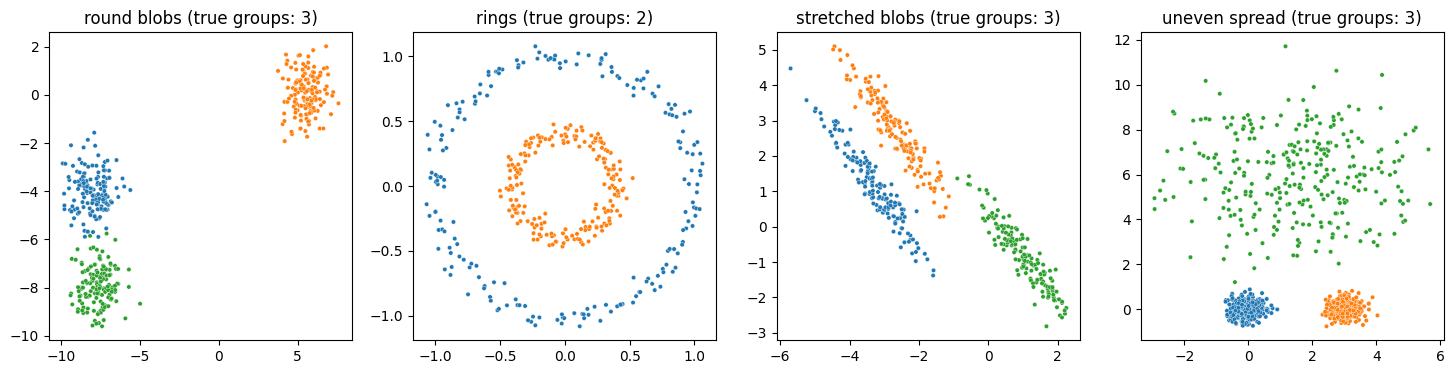

In [16]:
# RUN-TOGETHER  (Part D setup): four made-up datasets with known groups
from sklearn.datasets import make_blobs, make_circles

shapes = {}
pts, truth = make_blobs(n_samples=450, centers=3, cluster_std=0.8, random_state=210)
shapes['round blobs'] = (pts, truth, 3)

pts, truth = make_circles(n_samples=400, factor=0.4, noise=0.05, random_state=210)
shapes['rings'] = (pts, truth, 2)

pts, truth = make_blobs(n_samples=450, centers=3, cluster_std=1.0, random_state=170)
shapes['stretched blobs'] = (pts @ np.array([[0.6, -0.6], [-0.4, 0.8]]), truth, 3)

pts, truth = make_blobs(n_samples=[300, 300, 300], centers=[[0, 0], [3, 0], [1.5, 6]],
                        cluster_std=[0.3, 0.3, 1.8], random_state=210)
shapes['uneven spread'] = (pts, truth, 3)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, (pts, truth, k)) in zip(axes, shapes.items()):
    sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=truth, palette='tab10', s=10, ax=ax, legend=False)
    ax.set_title(f'{name} (true groups: {k})')
plt.show()

### Problem D1. Predict, then test (5 points)

**(a) Predict first (2 points).** Before running the next cell, fill in the table with **Y** (finds the true groups) or **N** (does not). Each algorithm is given the true number of groups where it needs one; DBSCAN uses `eps = 0.35` on scaled data.

| dataset | k-means | Ward | DBSCAN | Gaussian mixture |
| --- | --- | --- | --- | --- |
| round blobs |  |  |  |  |
| rings |  |  |  |  |
| stretched blobs |  |  |  |  |
| uneven spread |  |  |  |  |

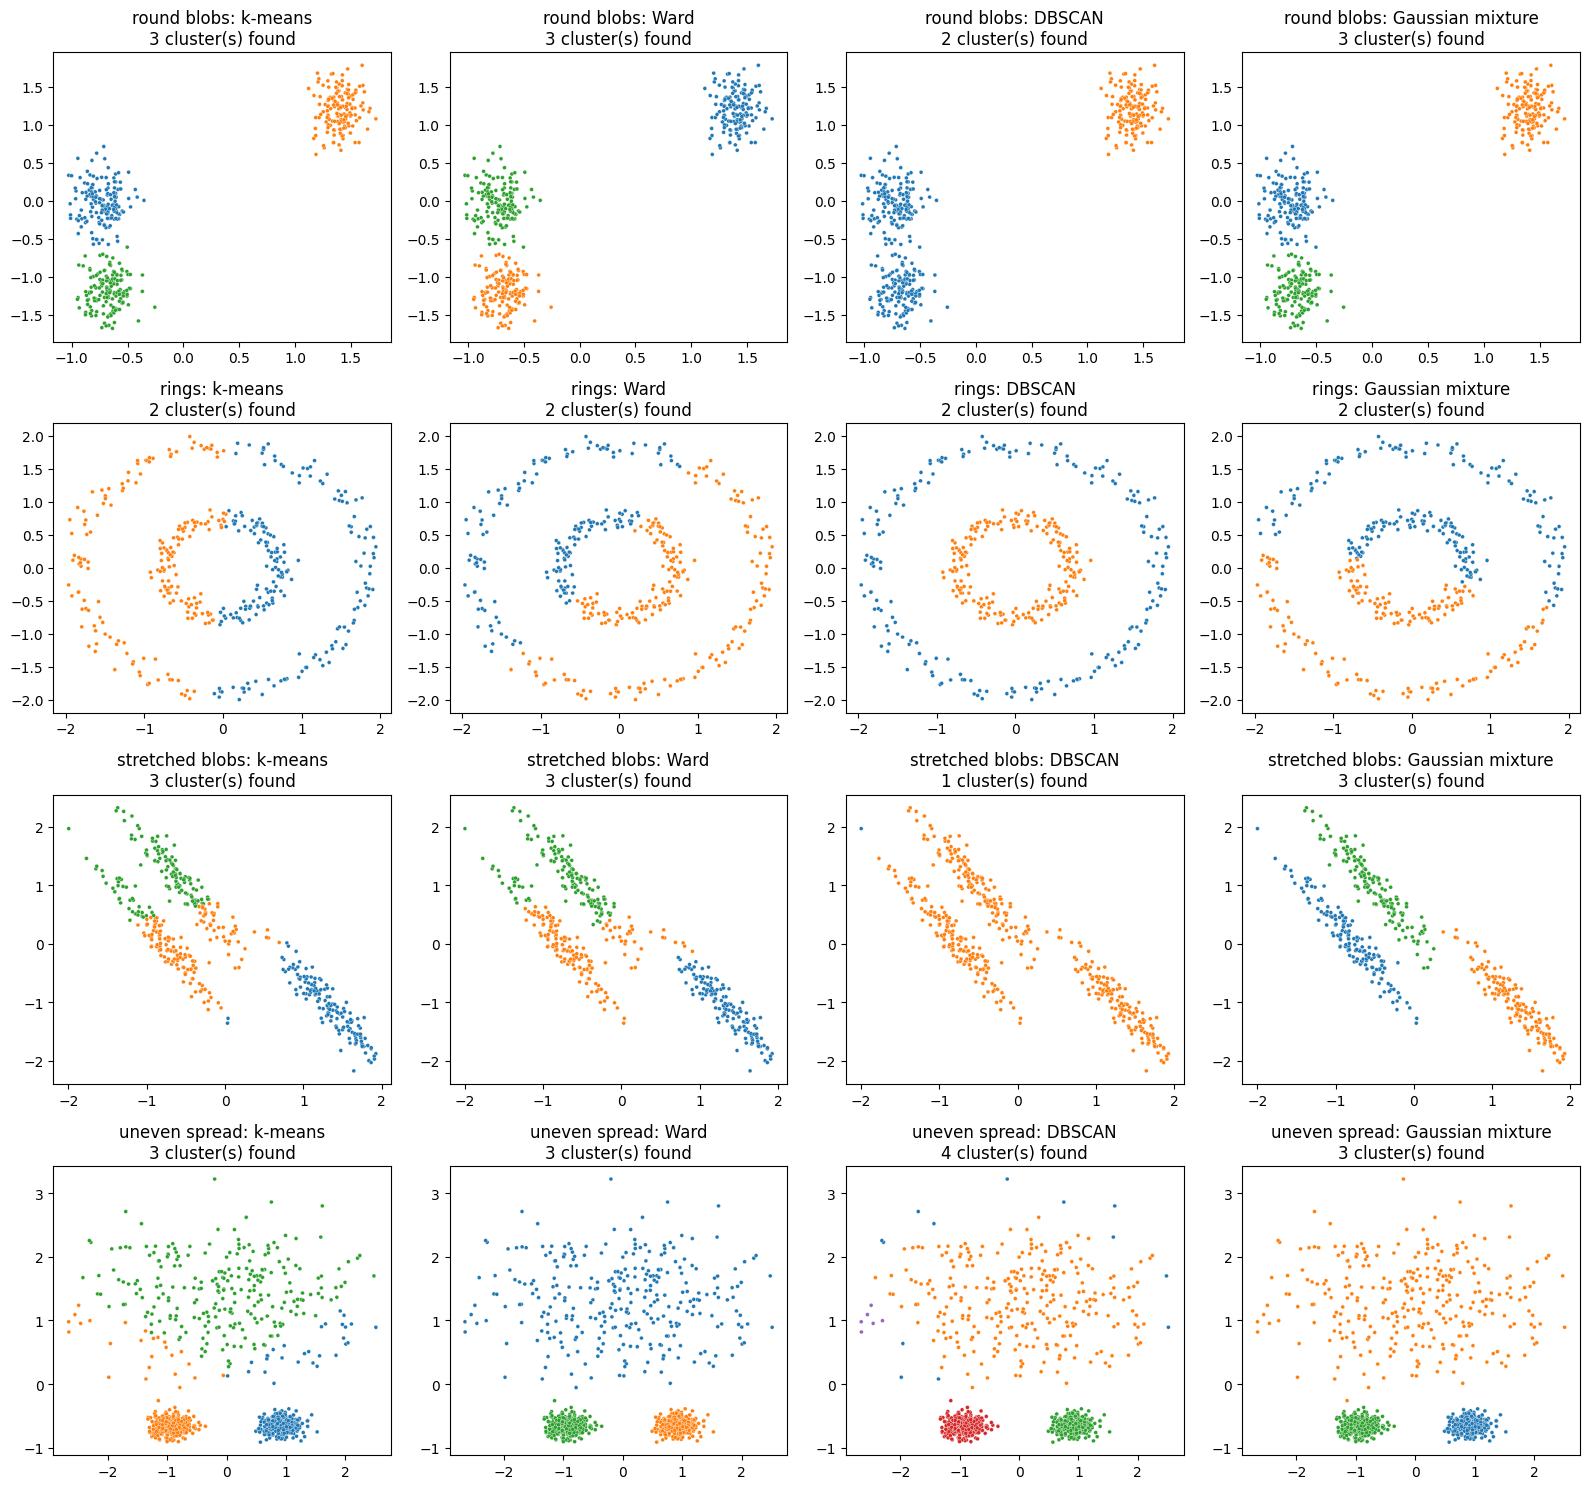

In [17]:
# RUN-TOGETHER  (Problem D1): every algorithm on every dataset
fig, axes = plt.subplots(4, 4, figsize=(16, 15))
for row, (name, (pts, truth, k)) in enumerate(shapes.items()):
    Xs = StandardScaler().fit_transform(pts)
    results = {
        'k-means': KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs).labels_,
        'Ward': fcluster(linkage(Xs, method='ward'), k, criterion='maxclust'),
        'DBSCAN': DBSCAN(eps=0.35, min_samples=5).fit(Xs).labels_,
        'Gaussian mixture': GaussianMixture(n_components=k, random_state=0).fit(Xs).predict(Xs),
    }
    for col, (method, labels) in enumerate(results.items()):
        ax = axes[row, col]
        sns.scatterplot(x=Xs[:, 0], y=Xs[:, 1], hue=labels, palette='tab10', s=8, ax=ax, legend=False)
        n_found = len(set(labels)) - (1 if -1 in set(labels) else 0)
        ax.set_title(f'{name}: {method}\n{n_found} cluster(s) found')
plt.tight_layout()
plt.show()

**(b) Score yourself (2 points).** Fill in what actually happened, and circle every cell where your prediction was wrong.

| dataset | k-means | Ward | DBSCAN | Gaussian mixture |
| --- | --- | --- | --- | --- |
| round blobs |  |  |  |  |
| rings |  |  |  |  |
| stretched blobs |  |  |  |  |
| uneven spread |  |  |  |  |

**(c) (1 point)** Is there one column with **Y** in every row? Connect your answer to the No Free Lunch theorem from Module 9.

**Your answer:**

(c)

> **SOLUTION**
>
> (a) Any honest prediction earns credit.
>
> (b) What happens (checked against the true groups):
>
> | dataset | k-means | Ward | DBSCAN | Gaussian mixture |
> | --- | --- | --- | --- | --- |
> | round blobs | Y | Y | N (merges two touching blobs into one: 2 clusters) | Y |
> | rings | N (cuts both rings in half) | N | Y (2 clusters) | N |
> | stretched blobs | N (cuts across the tilted blobs) | N (splits the two parallel blobs in the wrong place) | N (one cluster) | Y |
> | uneven spread | mostly (misassigns part of the wide blob) | Y | mostly (finds the three groups but adds a tiny fourth cluster and some noise at the edge of the wide blob) | Y |
>
> (c) No column is all **Y**. The Gaussian mixture comes closest but fails on the rings, which only DBSCAN finds; DBSCAN in turn fails on the round and stretched blobs. Each algorithm encodes an assumption about what a cluster is, and wins only where the data fits that assumption, as the No Free Lunch theorem says.

### Problem D2. Clusters in pure noise (3 points)

Module 9 warned: *"k-means asked for three clusters will produce three clusters from pure noise."* Test it.

cluster sizes: [ 89 125  86]


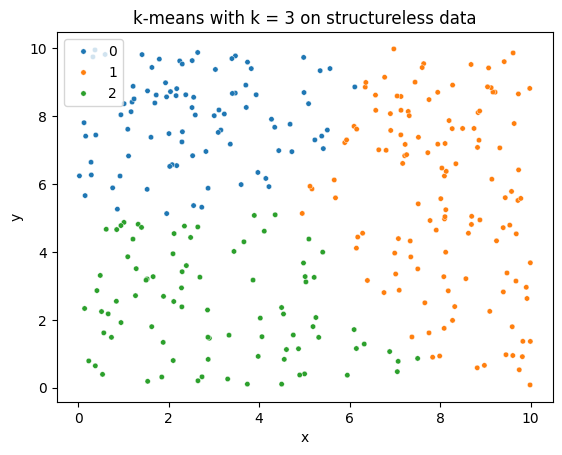

drops: [2134. 1213.  759.  195.  148.  138.  114.]


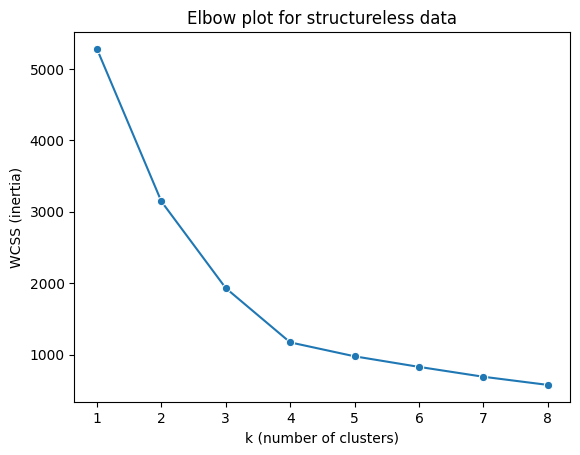

In [18]:
rng = np.random.default_rng(210)
noise = rng.uniform(0, 10, size=(300, 2))

km_noise = KMeans(n_clusters=3, n_init=10, random_state=0).fit(noise)
print('cluster sizes:', np.bincount(km_noise.labels_))
sns.scatterplot(x=noise[:, 0], y=noise[:, 1], hue=km_noise.labels_, palette='tab10', s=15)
plt.title('k-means with k = 3 on structureless data')
plt.xlabel('x'); plt.ylabel('y')
plt.show()

wcss_noise = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(noise).inertia_ for k in ks]
print('drops:', np.round(-np.diff(wcss_noise), 0))
sns.lineplot(x=list(ks), y=wcss_noise, marker='o')
plt.title('Elbow plot for structureless data')
plt.xlabel('k (number of clusters)')
plt.ylabel('WCSS (inertia)')
plt.xticks(list(ks))
plt.show()

(a) How large are the three "clusters"? Would the colored scatterplot alone convince a reader that the groups are real?

(b) Does the elbow plot for pure noise have a bend? What does this tell you about using an elbow plot as **proof** that clusters exist?

(c) The Pool 8 winter cluster passed several checks that this noise would fail. Name one.

**Your answer:**

(a)

(b)

(c)

> **SOLUTION**
>
> Blank: `3`.
>
> (a) 89, 125, and 86 points. The colored picture shows three tidy regions and looks convincing, even though the points were spread evenly with no groups at all.
>
> (b) Yes: the drops are 2134, 1213, 759, then 195, 148, ..., so the curve bends near k = 4 even in pure noise. An elbow can come from the geometry of splitting space; it is not proof of real groups.
>
> (c) Examples: the winter cluster matches a label the algorithm never saw (all 120 winter rows); it is found by every method (k-means, Ward, the mixture model); the Ward dendrogram shows a very large gap before the final merge (51.0 vs 33.0); and its centroid makes physical sense (cold, oxygen-rich, clear water).

---
## Part E. Report to the biologist (8 points)
---

Write for the biologist, who knows rivers well but has never run a clustering algorithm.

**(a) (3 points) Answer the question.** In 3 to 5 sentences: do the water measurements alone sort the samples into seasons? Quote specific numbers from at least two methods.

**(b) (2 points) Method.** Which method would you show the biologist first, and why? One or two sentences.

**(c) (2 points) Two cautions.** Name two things the biologist should keep in mind before trusting these clusters (for example, about scaling, the choice of k, or what one row of the data is).

**(d) (1 point) One follow-up.** Name one sample or group of samples you would ask the biologist about, and why.

**Your answer:**

(a)

(b)

(c)

(d)

> **SOLUTION**
>
> **(a) Sample answer.** Partly. Winter separates cleanly: k-means with k = 2 put all 120 winter samples (plus 10 fall and spring samples) in their own group, and Ward clustering's two-group cut is exactly winter vs everything else, with a very large gap in the dendrogram. Spring, summer, and fall do not separate into their own groups. With four clusters, k-means found winter plus three open-water conditions (warm and clear, turbid, algae-rich) that each mix several seasons, and the mixture model was least sure about fall samples (18 of the 30 uncertain samples). The measurements seem to describe water conditions that change gradually through the open-water seasons, with a sharp change under winter conditions.
>
> **(b)** Ward's dendrogram, because it shows the strong two-group structure and the weaker structure below it in one picture, without fixing k in advance. (Accept other defended choices.)
>
> **(c) Examples:** results depend on scaling (unscaled data clustered on conductance); k = 4 is a choice, not a discovery, since the elbow is unclear beyond k = 2; each row is a median for a habitat and season, not a single water sample; 8 rows with missing values were dropped; algorithms return clusters even for structureless data; cluster names are interpretations.
>
> **(d) Examples:** the DBSCAN noise points with very high chlorophyll (for example summer 2006 in the main channel and side channel), to ask whether these were algae blooms; or the 6 spring samples that clustered with winter, to ask whether they were sampled under ice or very cold conditions.